# 01 – Data exploration, cleaning and splitting
Dataset: Sri Lankan used vehicle listings from ikman.lk and riyasewana.com(Kaggle). Target `Price` is in units of LKR 100,000.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, joblib
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from common import *
sns.set_theme(style="whitegrid")
df = pd.read_csv(DATA/"car_prices.csv")
print(df.shape); display(df.head()); display(df.isna().sum().to_frame("missing").T); display(df.describe().T)

(9788, 17)


,Unnamed: 0,Brand,Model,YOM,Engine (cc),Gear,Fuel Type,Millage(KM),Town,Date,Leasing,Condition,AIR CONDITION,POWER STEERING,POWER MIRROR,POWER WINDOW,Price
0,0,AUDI,A1,2016,990.0,Automatic,Petrol,99000.0,Gampaha,2025-02-05,No Leasing,USED,Available,Available,Available,Available,100.0
1,1,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Colombo,2025-01-14,No Leasing,USED,Available,Available,Available,Available,97.0
2,2,AUDI,A1,2018,1000.0,Automatic,Petrol,77000.0,Dehiwala-Mount-Lavinia,2025-01-23,No Leasing,USED,Available,Available,Available,Available,98.5
3,3,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Negombo,2024-12-21,No Leasing,USED,Available,Available,Available,Available,107.0
4,4,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Colombo,2024-12-21,No Leasing,USED,Available,Available,Available,Available,99.5


,Unnamed: 0,Brand,Model,YOM,Engine (cc),Gear,Fuel Type,Millage(KM),Town,Date,Leasing,Condition,AIR CONDITION,POWER STEERING,POWER MIRROR,POWER WINDOW,Price
missing,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,9788.0,4893.758991,2826.028988,0.00,2446.75,4893.5,7341.25,9788.0
YOM,9788.0,2006.759093,9.831574,1956.00,2001.00,2009.0,2015.00,2024.0
Engine (cc),9788.0,1260.442358,403.769059,573.00,1000.00,1300.0,1500.00,4800.0
Millage(KM),9788.0,200649.979567,108147.314860,11000.00,110000.00,176000.0,264000.00,759000.0
Price,9788.0,53.464275,43.625049,2.65,26.25,43.0,69.75,790.0


## Cleaning and feature preparation

In [2]:
df = df.drop(columns=["Unnamed: 0"]).drop_duplicates()
df = df.rename(columns={"Millage(KM)":"Mileage","Engine (cc)":"Engine","AIR CONDITION":"AC","POWER STEERING":"PS","POWER MIRROR":"PM","POWER WINDOW":"PW"})
for c in ["AC","PS","PM","PW"]: df[c] = (df[c]=="Available").astype(int)
df["Leasing"] = (df["Leasing"]!="No Leasing").astype(int)
df["IsNew"]   = (df["Condition"]=="NEW").astype(int)
df["log_price"] = np.log1p(df["Price"])
print("rows after removing duplicates:", len(df))
df.to_csv(PROC/"clean.csv", index=False)

rows after removing duplicates: 9770


## Exploratory data analysis

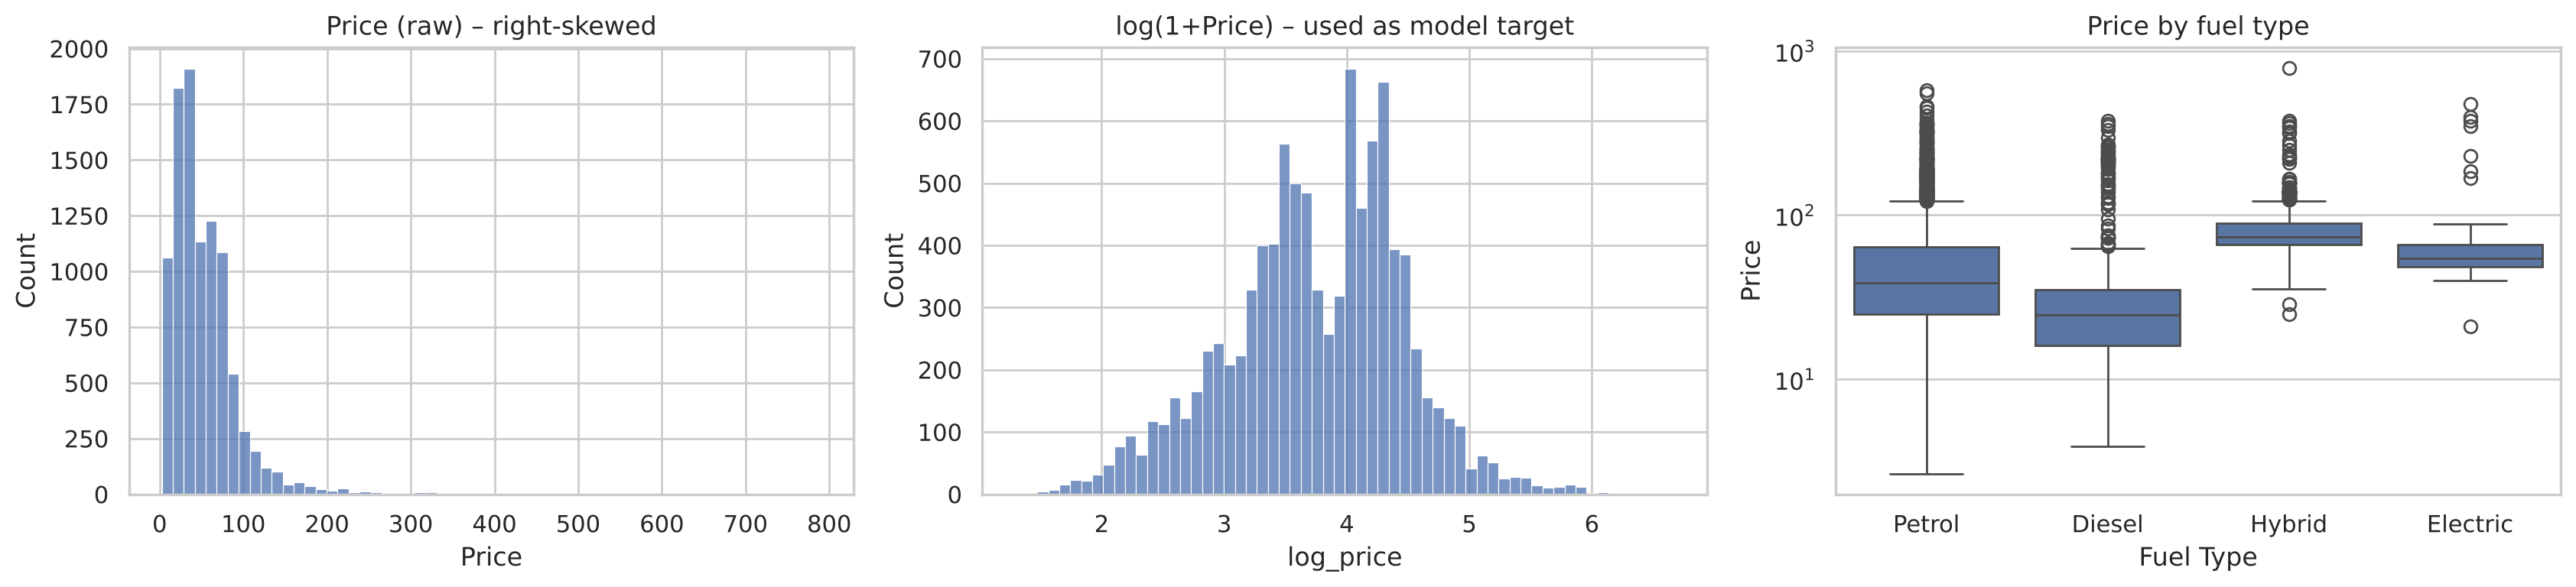

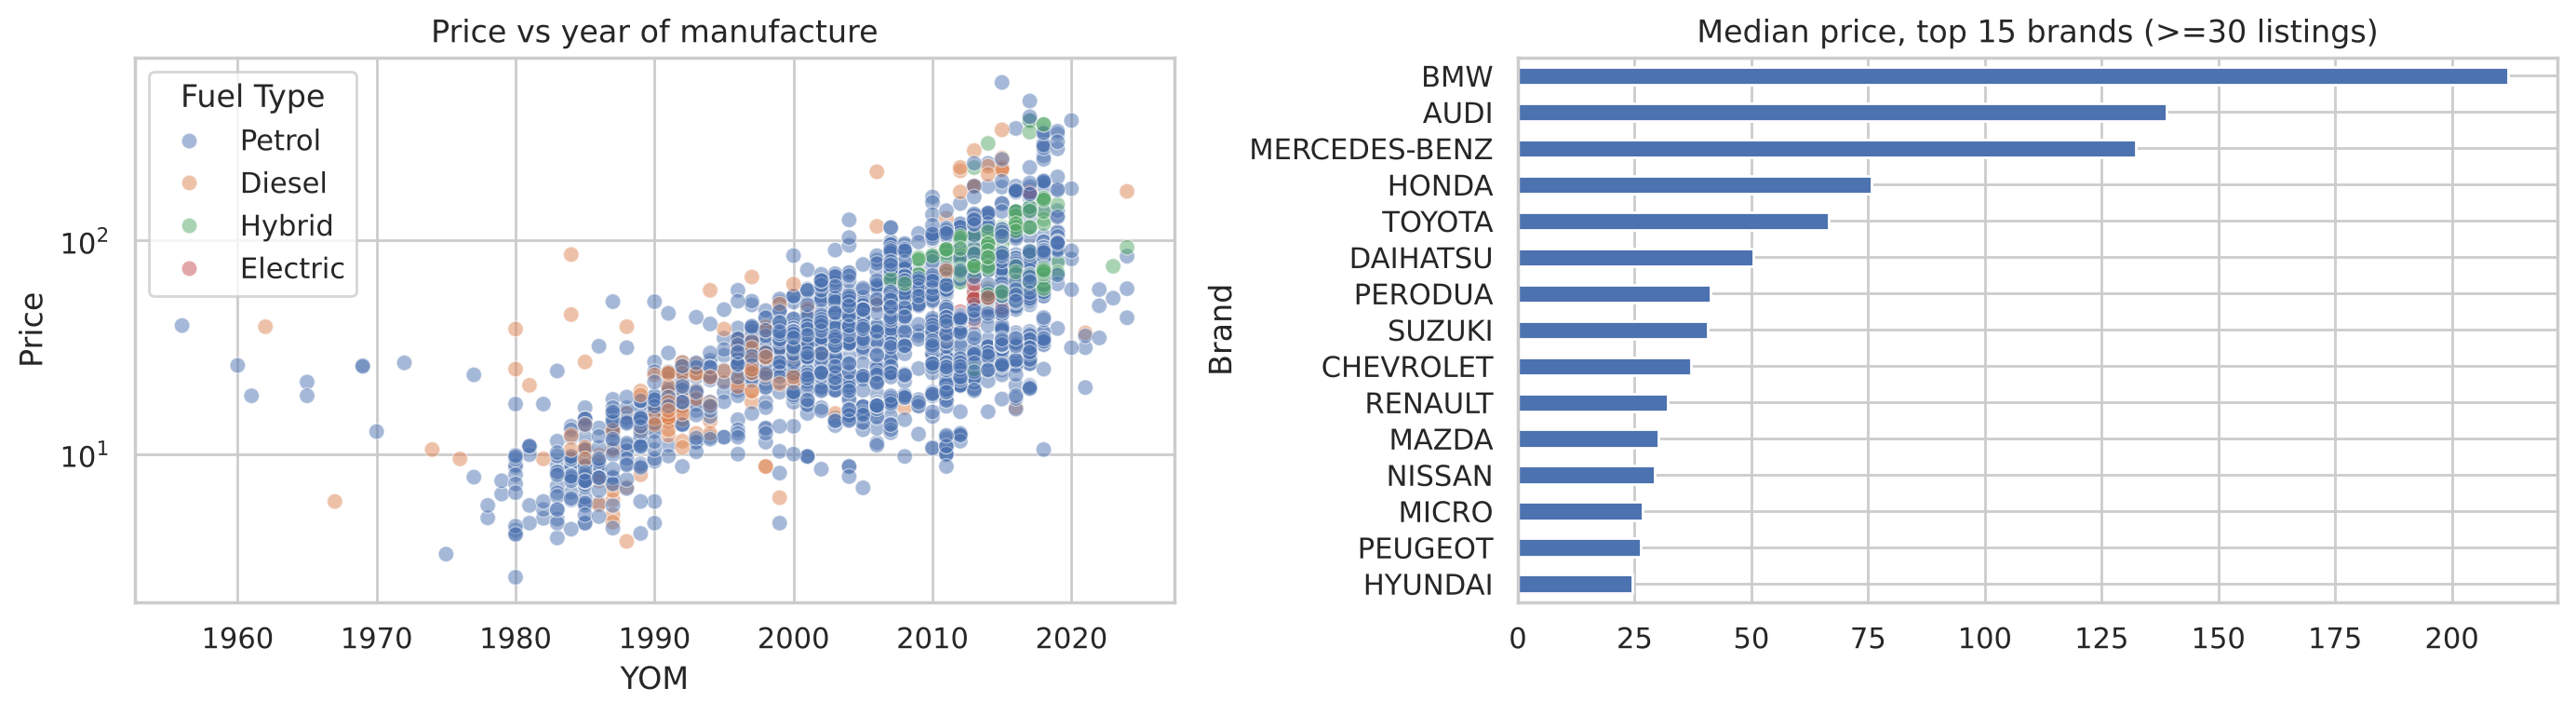

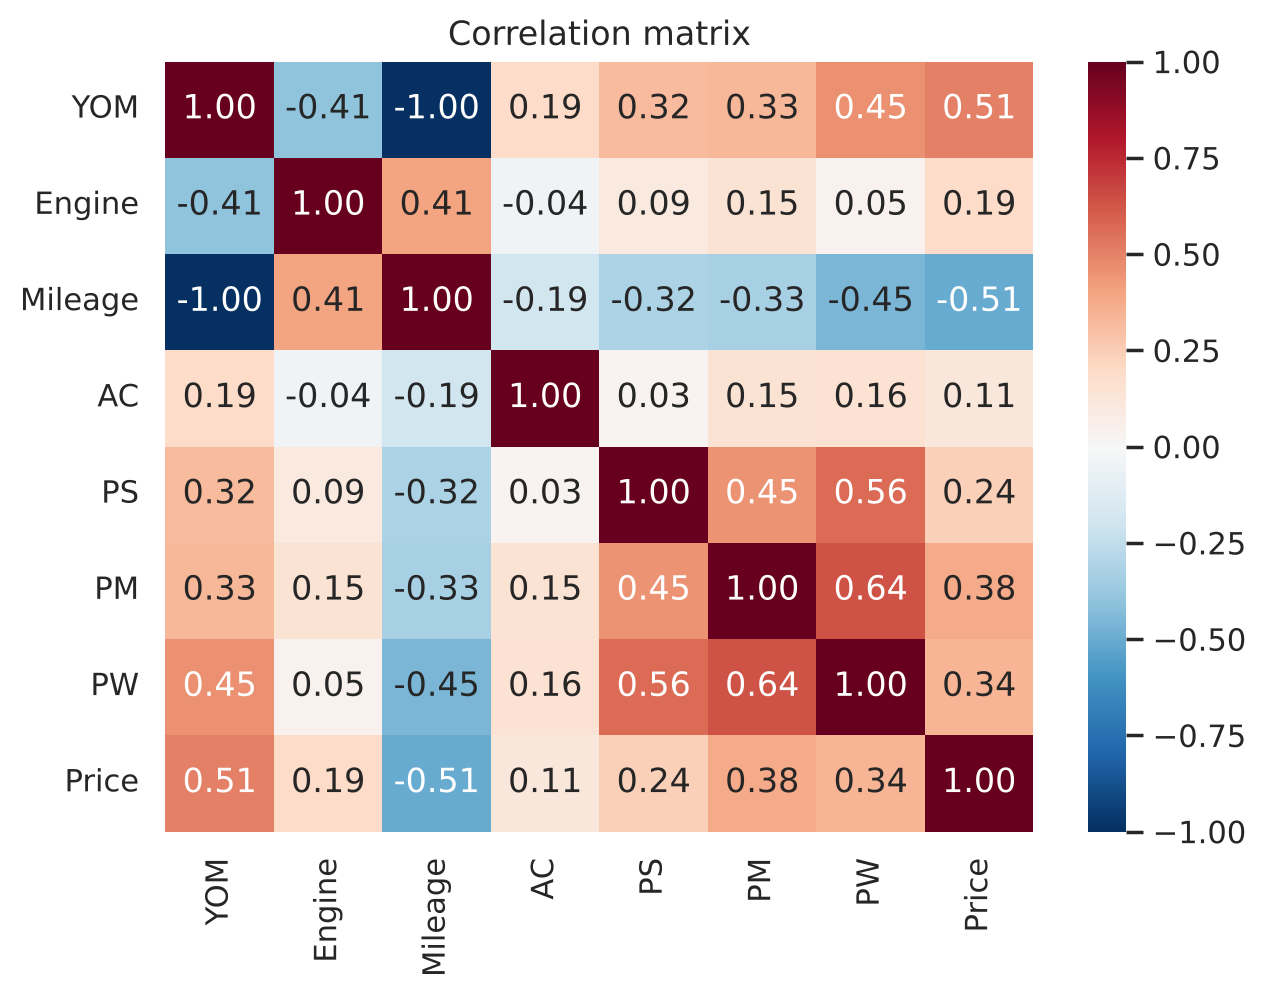

corr(YOM, Mileage) = -1.0 | distinct mileage values: 62


In [3]:
fig,ax = plt.subplots(1,3,figsize=(17,4))
sns.histplot(df.Price,bins=60,ax=ax[0]).set(title="Price (raw) – right-skewed")
sns.histplot(df.log_price,bins=60,ax=ax[1]).set(title="log(1+Price) – used as model target")
sns.boxplot(data=df,x="Fuel Type",y="Price",ax=ax[2]).set(yscale="log",title="Price by fuel type")
plt.tight_layout(); plt.show()
fig,ax = plt.subplots(1,2,figsize=(14,4))
sns.scatterplot(data=df.sample(3000,random_state=1),x="YOM",y="Price",hue="Fuel Type",alpha=.5,ax=ax[0]).set(yscale="log",title="Price vs year of manufacture")
top = df.groupby("Brand").Price.agg(["median","count"]).query("count>=30").sort_values("median",ascending=False).head(15)
top["median"].plot.barh(ax=ax[1]).set(title="Median price, top 15 brands (>=30 listings)"); ax[1].invert_yaxis()
plt.tight_layout(); plt.show()
plt.figure(figsize=(7,5)); sns.heatmap(df[["YOM","Engine","Mileage","AC","PS","PM","PW","Price"]].corr(),annot=True,fmt=".2f",cmap="RdBu_r",center=0); plt.title("Correlation matrix"); plt.show()
print("corr(YOM, Mileage) =", round(df.YOM.corr(df.Mileage),3), "| distinct mileage values:", df.Mileage.nunique())

## Train / validation / test split and shared preprocessing

In [4]:
train, tmp = train_test_split(df, test_size=0.30, random_state=SEED)
val, test  = train_test_split(tmp, test_size=0.50, random_state=SEED)
for n,d in [("train",train),("val",val),("test",test)]:
    d[CAT+NUM+["Price","log_price"]].to_csv(PROC/f"{n}.csv", index=False); print(n, len(d))

pre = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=5, sparse_output=False), CAT),
    ("num", StandardScaler(), NUM)])
pre.fit(train[CAT+NUM])                      # fitted on training data only -> no leakage
joblib.dump(pre, MODELS/"preprocessor.pkl")
print("encoded feature matrix width:", pre.transform(train[CAT+NUM]).shape[1])

train 6839
val 1465
test 1466


encoded feature matrix width: 371
